# Kriptanalisis Substitusi Monoalfabetik
## Random-Restart Steepest-Ascent Hill Climbing + Skor Quadgram

Notebook ini adalah implementasi dan eksperimen untuk paper. Jalankan dari atas ke bawah (**Runtime → Run all**).

| Bagian | Isi | Dipakai di paper |
|---|---|---|
| 1 | Konfigurasi eksperimen | Metode (parameter) |
| 2 | Korpus dan normalisasi teks | Metode (data) |
| 3 | Model bahasa quadgram dan fungsi skor S(P) | Persamaan (1) |
| 4 | Cipher substitusi dan representasi kunci | Landasan teori |
| 5 | Steepest-Ascent Hill Climbing + Random Restart | Algoritma / pseudocode |
| 6 | Demo satu cipherteks | Contoh hasil, kurva konvergensi |
| 7 | Eksperimen utama (panjang × jumlah restart) | Hasil |
| 8 | Tabel hasil | Tabel I–III |
| 9 | Grafik | Gambar |
| 10 | Analisis skor vs akurasi | Pembahasan |
| 11 | Simpan dan unduh semua keluaran | Lampiran |
| 12 | Coba cipherteks sendiri | Demonstrasi |

## 1. Konfigurasi eksperimen

In [ ]:
import time, os, re, math, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------- PARAMETER EKSPERIMEN ----------------
PANJANG_TEKS   = [100, 250, 500, 1000]   # panjang cipherteks (jumlah huruf)
JUMLAH_RESTART = [1, 5, 10, 30]          # konfigurasi jumlah titik awal
N_TEKS         = 30                      # jumlah cipherteks berbeda per panjang
MAKS_ITERASI   = 1000                    # batas langkah per satu pendakian
AMBANG_PULIH   = 0.99                    # akurasi karakter >= ambang -> "pulih"
SEED           = 2026                    # seed agar hasil dapat diulang

# Korpus (NLTK Gutenberg). Model bahasa dan teks uji memakai buku yang BERBEDA.
BUKU_LATIH = ['austen-emma.txt', 'austen-sense.txt', 'melville-moby_dick.txt',
              'edgeworth-parents.txt', 'bryant-stories.txt', 'carroll-alice.txt',
              'whitman-leaves.txt']
BUKU_UJI   = ['chesterton-thursday.txt', 'chesterton-brown.txt']

OUT = 'hasil'
os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 10})

## 2. Korpus dan normalisasi teks

Normalisasi: semua huruf dijadikan kapital, lalu semua karakter selain A–Z (spasi, angka, tanda baca) dibuang.

In [ ]:
def muat_korpus():
    # Mengembalikan fungsi baca(nama_file) -> teks mentah.
    try:
        import nltk
        nltk.download('gutenberg', quiet=True)
        from nltk.corpus import gutenberg
        gutenberg.fileids()
        return lambda nama: gutenberg.raw(nama)
    except Exception as e:
        print('NLTK gagal (%s), mengunduh zip langsung...' % type(e).__name__)
        url = 'https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/packages/corpora/gutenberg.zip'
        if not os.path.exists('gutenberg.zip'):
            urllib.request.urlretrieve(url, 'gutenberg.zip')
        z = zipfile.ZipFile('gutenberg.zip')
        return lambda nama: z.read('gutenberg/' + nama).decode('latin-1')

def normalisasi(teks):
    # Huruf kapital A-Z saja.
    return re.sub('[^A-Z]', '', teks.upper())

def ke_angka(s):
    # 'ABC' -> array [0, 1, 2]
    return np.frombuffer(s.encode('ascii'), dtype=np.uint8).astype(np.int64) - 65

def ke_huruf(a):
    return (np.asarray(a) + 65).astype(np.uint8).tobytes().decode('ascii')

baca = muat_korpus()
teks_latih = normalisasi(' '.join(baca(b) for b in BUKU_LATIH))
teks_uji   = normalisasi(' '.join(baca(b) for b in BUKU_UJI))
print('Korpus latih : %d huruf dari %d buku' % (len(teks_latih), len(BUKU_LATIH)))
print('Korpus uji   : %d huruf dari %d buku' % (len(teks_uji), len(BUKU_UJI)))

Korpus latih : 3689266 huruf dari 7 buku
Korpus uji   : 560654 huruf dari 2 buku


## 3. Model bahasa quadgram dan fungsi skor

$$S(P)=\sum_{i=1}^{L-3}\log_{10} p\left(P_iP_{i+1}P_{i+2}P_{i+3}\right)$$

- $p$ = frekuensi relatif quadgram pada korpus latih.
- Quadgram yang tidak pernah muncul diberi nilai lantai $\log_{10}(0{,}01/N)$, dengan $N$ = total quadgram korpus, sehingga tidak pernah bernilai $-\infty$.
- Tabel disimpan sebagai array berukuran $26^4 = 456.976$; indeks quadgram $= 26^3a + 26^2b + 26c + d$.

In [ ]:
def indeks_quadgram(x):
    # x: array angka 0..25 dengan sumbu terakhir = posisi huruf.
    return (x[..., :-3] * 17576 + x[..., 1:-2] * 676 + x[..., 2:-1] * 26 + x[..., 3:])

def bangun_model(teks):
    idx = indeks_quadgram(ke_angka(teks))
    hitung = np.bincount(idx, minlength=26 ** 4).astype(np.float64)
    N = hitung.sum()
    lantai = math.log10(0.01 / N)
    with np.errstate(divide='ignore'):
        logp = np.where(hitung > 0, np.log10(hitung / N), lantai)
    return logp, N, lantai, int((hitung > 0).sum())

LOGP, N_QUAD, LANTAI, N_UNIK = bangun_model(teks_latih)
print('Total quadgram N     : %d' % N_QUAD)
print('Quadgram unik        : %d dari %d (%.1f%%)' % (N_UNIK, 26 ** 4, 100 * N_UNIK / 26 ** 4))
print('Nilai lantai log10   : %.3f' % LANTAI)

def skor(p):
    # S(P) untuk plainteks kandidat p (array angka). Bisa 1 teks atau banyak (2D).
    return LOGP[indeks_quadgram(p)].sum(axis=-1)

# Uji cepat: teks Inggris harus bernilai jauh lebih tinggi daripada huruf acak.
contoh = ke_angka(teks_uji[:500])
acak = np.random.default_rng(0).integers(0, 26, 500)
print('Skor per quadgram, teks Inggris : %.3f' % (skor(contoh) / 497))
print('Skor per quadgram, huruf acak   : %.3f' % (skor(acak) / 497))

Total quadgram N     : 3689263
Quadgram unik        : 69341 dari 456976 (15.2%)
Nilai lantai log10   : -8.567
Skor per quadgram, teks Inggris : -4.277
Skor per quadgram, huruf acak   : -8.133


## 4. Cipher substitusi dan representasi kunci

Kunci dekripsi adalah permutasi 26 huruf: **indeks ke-i mewakili huruf cipherteks ke-i, dan nilainya adalah dugaan huruf plainteks**. Contoh: `kunci[0] = 19` berarti cipherteks `A` didekripsi menjadi `T`.

In [ ]:
def kunci_acak(rng):
    return rng.permutation(26)

def enkripsi(plain, rng):
    # Mengembalikan (cipherteks, kunci_dekripsi_benar).
    kunci_enk = rng.permutation(26)          # plainteks -> cipherteks
    kunci_dek = np.argsort(kunci_enk)        # cipherteks -> plainteks
    return kunci_enk[plain], kunci_dek

def dekripsi(cipher, kunci):
    return kunci[cipher]

# Uji cepat
_rng = np.random.default_rng(1)
_p = ke_angka('THEQUICKBROWNFOXJUMPSOVERTHELAZYDOG')
_c, _k = enkripsi(_p, _rng)
print('Plainteks  :', ke_huruf(_p))
print('Cipherteks :', ke_huruf(_c))
print('Dekripsi   :', ke_huruf(dekripsi(_c, _k)))
assert (dekripsi(_c, _k) == _p).all()

Plainteks  : THEQUICKBROWNFOXJUMPSOVERTHELAZYDOG
Cipherteks : JQRFOZHCUIDWKPDNLOMEADSRIJQRXBTGVDY
Dekripsi   : THEQUICKBROWNFOXJUMPSOVERTHELAZYDOG


## 5. Steepest-Ascent Hill Climbing dengan Random Restart

**Tetangga** = kunci hasil pertukaran (*swap*) dua nilai, sehingga ada $C(26,2)=325$ tetangga per langkah.

```
untuk r = 1 .. R:                          # random restart
    kunci <- permutasi acak
    ulangi:
        hitung skor ke-325 tetangga kunci
        t* <- tetangga dengan skor tertinggi
        jika skor(t*) <= skor(kunci): berhenti      # optimum lokal
        kunci <- t*
    simpan kunci jika skornya terbaik sejauh ini
kembalikan kunci terbaik
```

Seri (skor sama) diselesaikan dengan memilih tetangga pertama pada urutan pasangan $(i,j)$. Ke-325 tetangga dihitung sekaligus dengan NumPy agar cepat.

In [ ]:
PASANGAN = np.array([(i, j) for i in range(26) for j in range(i + 1, 26)])
PI, PJ = PASANGAN[:, 0], PASANGAN[:, 1]
BARIS = np.arange(len(PASANGAN))
assert len(PASANGAN) == 325

def semua_tetangga(kunci):
    # Matriks 325 x 26: baris ke-n = kunci dengan posisi PI[n] dan PJ[n] ditukar.
    T = np.tile(kunci, (325, 1))
    T[BARIS, PI] = kunci[PJ]
    T[BARIS, PJ] = kunci[PI]
    return T

def hill_climb(cipher, kunci_awal, maks_iterasi=MAKS_ITERASI):
    # Satu pendakian steepest-ascent dari satu kunci awal.
    kunci = kunci_awal.copy()
    s = skor(kunci[cipher])
    evaluasi = 1
    riwayat = [s]
    for _ in range(maks_iterasi):
        T = semua_tetangga(kunci)
        s_tetangga = skor(T[:, cipher])          # skor 325 kandidat sekaligus
        evaluasi += 325
        terbaik = int(np.argmax(s_tetangga))
        if s_tetangga[terbaik] <= s + 1e-9:      # tidak ada perbaikan -> optimum lokal
            break
        kunci, s = T[terbaik], s_tetangga[terbaik]
        riwayat.append(s)
    return kunci, s, evaluasi, riwayat

def random_restart(cipher, n_restart, rng):
    # Menjalankan n_restart pendakian; mengembalikan catatan tiap restart.
    catatan = []
    for r in range(n_restart):
        t0 = time.perf_counter()
        kunci, s, ev, riwayat = hill_climb(cipher, kunci_acak(rng))
        catatan.append({'restart': r + 1, 'kunci': kunci, 'skor': s, 'evaluasi': ev,
                        'langkah': len(riwayat) - 1, 'waktu': time.perf_counter() - t0,
                        'riwayat': riwayat})
    return catatan

def akurasi_karakter(plain_tebakan, plain_asli):
    return float((plain_tebakan == plain_asli).mean())

def akurasi_kunci(kunci, kunci_benar, cipher):
    # Hanya dihitung pada huruf cipherteks yang benar-benar muncul.
    muncul = np.unique(cipher)
    return float((kunci[muncul] == kunci_benar[muncul]).mean())

## 6. Demo satu cipherteks

Cipherteks : UVFYSRYNYNVPSDSVPAVDBYXDPYWXTSDUSCGZYXAYNXAYIVBGCIXIVYNXBECFVBACZDFDSAYIUVWDPSCLDWXDJITJJD ...
Hasil      : FAVIRGININAPRERAPHAELITEPICTUREFROMWITHINTHISALMOSTSAINTLYOVALHOWEVERHISFACEPROJECTEDSUDDE ...
Plainteks  : FAVIRGININAPRERAPHAELITEPICTUREFROMWITHINTHISALMOSTSAINTLYOVALHOWEVERHISFACEPROJECTEDSUDDE ...

Skor hasil / skor plainteks asli : -2087.79 / -2087.79
Akurasi karakter                 : 100.00%
Akurasi kunci                    : 100.00%
Total evaluasi kandidat          : 97835
Total waktu                      : 1.43 detik


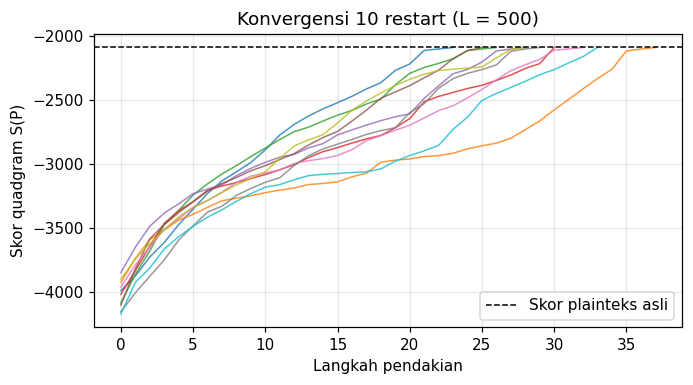

,Restart,Skor akhir,Langkah,Evaluasi,Akurasi karakter (%)
0,1,-2087.79,23,7801,100.0
1,2,-2087.79,37,12351,100.0
2,3,-2087.79,26,8776,100.0
3,4,-2087.79,30,10076,100.0
4,5,-2087.79,28,9426,100.0
5,6,-2087.79,25,8451,100.0
6,7,-2087.79,32,10726,100.0
7,8,-2087.79,29,9751,100.0
8,9,-2087.79,28,9426,100.0
9,10,-2087.79,33,11051,100.0


In [ ]:
rng = np.random.default_rng(SEED)
plain = ke_angka(teks_uji[5000:5500])            # 500 huruf dari korpus uji
cipher, kunci_benar = enkripsi(plain, rng)

catatan = random_restart(cipher, 10, rng)
terbaik = max(catatan, key=lambda c: c['skor'])
hasil = dekripsi(cipher, terbaik['kunci'])

print('Cipherteks :', ke_huruf(cipher)[:90], '...')
print('Hasil      :', ke_huruf(hasil)[:90], '...')
print('Plainteks  :', ke_huruf(plain)[:90], '...')
print()
print('Skor hasil / skor plainteks asli : %.2f / %.2f' % (terbaik['skor'], skor(plain)))
print('Akurasi karakter                 : %.2f%%' % (100 * akurasi_karakter(hasil, plain)))
print('Akurasi kunci                    : %.2f%%' % (100 * akurasi_kunci(terbaik['kunci'], kunci_benar, cipher)))
print('Total evaluasi kandidat          : %d' % sum(c['evaluasi'] for c in catatan))
print('Total waktu                      : %.2f detik' % sum(c['waktu'] for c in catatan))

# Kurva konvergensi tiap restart
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for c in catatan:
    ax.plot(c['riwayat'], lw=1, alpha=.8)
ax.axhline(skor(plain), color='k', ls='--', lw=1, label='Skor plainteks asli')
ax.set_xlabel('Langkah pendakian'); ax.set_ylabel('Skor quadgram S(P)')
ax.set_title('Konvergensi 10 restart (L = 500)'); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT + '/gambar_konvergensi.png'); plt.show()

pd.DataFrame([{'Restart': c['restart'], 'Skor akhir': round(c['skor'], 2), 'Langkah': c['langkah'],
               'Evaluasi': c['evaluasi'],
               'Akurasi karakter (%)': round(100 * akurasi_karakter(dekripsi(cipher, c['kunci']), plain), 2)}
              for c in catatan])

## 7. Eksperimen utama

Untuk setiap panjang teks diambil `N_TEKS` potongan berbeda dari korpus uji, masing-masing dienkripsi dengan kunci acak yang berbeda.

Setiap cipherteks dijalankan dengan 30 restart, dan hasil tiap restart dicatat. Konfigurasi *R* restart dihitung dari **R restart pertama**: kandidat dengan skor tertinggi dipilih (tanpa melihat plainteks asli), sedangkan waktu dan jumlah evaluasi dijumlahkan. Dengan begitu keempat konfigurasi dibandingkan pada cipherteks dan titik awal yang sama, sehingga perbedaannya murni akibat jumlah restart.

Perkiraan waktu di Colab: beberapa menit.

In [ ]:
rng = np.random.default_rng(SEED)
R_MAKS = max(JUMLAH_RESTART)
baris_restart = []     # satu baris per (teks, restart)
baris_konfig  = []     # satu baris per (teks, konfigurasi R)

t_mulai = time.perf_counter()
for L in PANJANG_TEKS:
    awal = rng.choice(len(teks_uji) - L, size=N_TEKS, replace=False)
    for id_teks, a in enumerate(awal):
        plain = ke_angka(teks_uji[a:a + L])
        cipher, kunci_benar = enkripsi(plain, rng)
        skor_asli = float(skor(plain))
        catatan = random_restart(cipher, R_MAKS, rng)
        for c in catatan:
            c['akurasi'] = akurasi_karakter(dekripsi(cipher, c['kunci']), plain)
            c['akurasi_kunci'] = akurasi_kunci(c['kunci'], kunci_benar, cipher)
            baris_restart.append({'panjang': L, 'id_teks': id_teks, 'restart': c['restart'],
                                  'skor': c['skor'], 'skor_asli': skor_asli, 'akurasi': c['akurasi'],
                                  'akurasi_kunci': c['akurasi_kunci'], 'langkah': c['langkah'],
                                  'evaluasi': c['evaluasi'], 'waktu': c['waktu']})
        for R in JUMLAH_RESTART:
            sub = catatan[:R]
            b = max(sub, key=lambda c: c['skor'])
            baris_konfig.append({'panjang': L, 'id_teks': id_teks, 'n_restart': R,
                                 'skor': b['skor'], 'skor_asli': skor_asli,
                                 'akurasi': b['akurasi'], 'akurasi_kunci': b['akurasi_kunci'],
                                 'pulih': b['akurasi'] >= AMBANG_PULIH,
                                 'evaluasi': sum(c['evaluasi'] for c in sub),
                                 'waktu': sum(c['waktu'] for c in sub)})
    print('L = %4d selesai | waktu berjalan %.0f detik' % (L, time.perf_counter() - t_mulai))

df_restart = pd.DataFrame(baris_restart)
df = pd.DataFrame(baris_konfig)
df_restart.to_csv(OUT + '/data_per_restart.csv', index=False)
df.to_csv(OUT + '/data_per_konfigurasi.csv', index=False)
print('Selesai. %d pendakian, total %.0f detik.' % (len(df_restart), time.perf_counter() - t_mulai))

L =  100 selesai | waktu berjalan 8 detik
L =  250 selesai | waktu berjalan 26 detik
L =  500 selesai | waktu berjalan 71 detik
L = 1000 selesai | waktu berjalan 157 detik
Selesai. 3600 pendakian, total 157 detik.


## 8. Tabel hasil

- **Akurasi karakter**: persentase huruf hasil dekripsi yang sama dengan plainteks asli.
- **Tingkat pemulihan**: persentase cipherteks dengan akurasi karakter ≥ ambang (`AMBANG_PULIH`).
- **Kestabilan**: simpangan baku akurasi antar-cipherteks (semakin kecil semakin stabil).

In [ ]:
g = df.groupby(['panjang', 'n_restart'])
ringkas = g.agg(akurasi_rata=('akurasi', 'mean'), akurasi_sd=('akurasi', 'std'),
                akurasi_min=('akurasi', 'min'), akurasi_kunci=('akurasi_kunci', 'mean'),
                tingkat_pulih=('pulih', 'mean'), evaluasi=('evaluasi', 'mean'),
                waktu=('waktu', 'mean')).reset_index()
for k in ['akurasi_rata', 'akurasi_sd', 'akurasi_min', 'akurasi_kunci', 'tingkat_pulih']:
    ringkas[k] *= 100
ringkas.to_csv(OUT + '/tabel_ringkasan.csv', index=False)

tampil = ringkas.rename(columns={
    'panjang': 'Panjang', 'n_restart': 'Restart', 'akurasi_rata': 'Akurasi karakter (%)',
    'akurasi_sd': 'Simpangan baku (%)', 'akurasi_min': 'Akurasi minimum (%)',
    'akurasi_kunci': 'Akurasi kunci (%)', 'tingkat_pulih': 'Tingkat pemulihan (%)',
    'evaluasi': 'Evaluasi kandidat', 'waktu': 'Waktu (detik)'})
tampil.style.format({'Akurasi karakter (%)': '{:.2f}', 'Simpangan baku (%)': '{:.2f}',
                     'Akurasi minimum (%)': '{:.2f}', 'Akurasi kunci (%)': '{:.2f}',
                     'Tingkat pemulihan (%)': '{:.1f}', 'Evaluasi kandidat': '{:,.0f}',
                     'Waktu (detik)': '{:.3f}'}).hide(axis='index')

Panjang,Restart,Akurasi karakter (%),Simpangan baku (%),Akurasi minimum (%),Akurasi kunci (%),Tingkat pemulihan (%),Evaluasi kandidat,Waktu (detik)
100,1,12.50,14.47,0.00,9.85,0.0,"5,699",0.008
100,5,44.97,35.55,0.00,38.56,13.3,"29,699",0.046
100,10,52.87,35.47,0.00,44.90,16.7,"58,672",0.089
100,30,78.23,27.37,10.00,69.23,33.3,"175,530",0.258
250,1,37.28,40.39,0.00,36.77,23.3,"7,054",0.020
250,5,89.76,26.48,3.60,89.07,83.3,"36,622",0.106
250,10,95.95,17.98,3.60,95.64,93.3,"73,298",0.210
250,30,99.19,4.38,76.00,99.10,96.7,"214,942",0.617
500,1,65.32,43.73,0.00,65.61,60.0,"8,094",0.048
500,5,100.00,0.00,100.00,100.00,100.0,"40,912",0.246


In [ ]:
# Tabel silang (panjang x jumlah restart), siap disalin ke paper.
def silang(kolom, judul, fmt):
    t = ringkas.pivot(index='panjang', columns='n_restart', values=kolom)
    t.index.name = 'Panjang teks'; t.columns.name = 'Jumlah restart'
    t.to_csv(OUT + '/tabel_' + kolom + '.csv')
    print(judul); display(t.style.format(fmt)); print()

silang('akurasi_rata',  'TABEL I. Rata-rata akurasi karakter (%)', '{:.2f}')
silang('tingkat_pulih', 'TABEL II. Tingkat pemulihan (%), ambang akurasi >= {:.0f}%'.format(AMBANG_PULIH * 100), '{:.1f}')
silang('akurasi_sd',    'TABEL III. Simpangan baku akurasi (%), ukuran kestabilan', '{:.2f}')
silang('waktu',         'TABEL IV. Rata-rata waktu pencarian (detik)', '{:.3f}')
silang('evaluasi',      'TABEL V. Rata-rata jumlah evaluasi kandidat', '{:,.0f}')

TABEL I. Rata-rata akurasi karakter (%)


Jumlah restart,1,5,10,30
Panjang teks,,,,
100,12.50,44.97,52.87,78.23
250,37.28,89.76,95.95,99.19
500,65.32,100.00,100.00,100.00
1000,69.91,100.00,100.00,100.00



TABEL II. Tingkat pemulihan (%), ambang akurasi >= 99%


Jumlah restart,1,5,10,30
Panjang teks,,,,
100,0.0,13.3,16.7,33.3
250,23.3,83.3,93.3,96.7
500,60.0,100.0,100.0,100.0
1000,63.3,100.0,100.0,100.0



TABEL III. Simpangan baku akurasi (%), ukuran kestabilan


Jumlah restart,1,5,10,30
Panjang teks,,,,
100,14.47,35.55,35.47,27.37
250,40.39,26.48,17.98,4.38
500,43.73,0.00,0.00,0.00
1000,40.79,0.00,0.00,0.00



TABEL IV. Rata-rata waktu pencarian (detik)


Jumlah restart,1,5,10,30
Panjang teks,,,,
100,0.008,0.046,0.089,0.258
250,0.020,0.106,0.210,0.617
500,0.048,0.246,0.497,1.470
1000,0.090,0.458,0.946,2.875



TABEL V. Rata-rata jumlah evaluasi kandidat


Jumlah restart,1,5,10,30
Panjang teks,,,,
100,"5,699","29,699","58,672","175,530"
250,"7,054","36,622","73,298","214,942"
500,"8,094","40,912","79,971","240,833"
1000,"8,213","41,432","83,752","252,544"


In [ ]:
# Perilaku satu pendakian (tanpa restart): dasar untuk menjelaskan optimum lokal.
g1 = df_restart.groupby('panjang')
satu = g1.agg(langkah=('langkah', 'mean'), evaluasi=('evaluasi', 'mean'), waktu=('waktu', 'mean'),
              akurasi=('akurasi', 'mean'),
              peluang_berhasil=('akurasi', lambda a: (a >= AMBANG_PULIH).mean())).reset_index()
satu['akurasi'] *= 100; satu['peluang_berhasil'] *= 100
satu.to_csv(OUT + '/tabel_satu_pendakian.csv', index=False)
print('TABEL VI. Statistik satu pendakian (rata-rata dari semua restart)')
satu.rename(columns={'panjang': 'Panjang', 'langkah': 'Langkah sampai berhenti', 'evaluasi': 'Evaluasi',
                     'waktu': 'Waktu (detik)', 'akurasi': 'Akurasi karakter (%)',
                     'peluang_berhasil': 'Peluang satu pendakian berhasil (%)'}
            ).style.format({'Langkah sampai berhenti': '{:.1f}', 'Evaluasi': '{:,.0f}', 'Waktu (detik)': '{:.3f}',
                            'Akurasi karakter (%)': '{:.2f}', 'Peluang satu pendakian berhasil (%)': '{:.1f}'}
                           ).hide(axis='index')

TABEL VI. Statistik satu pendakian (rata-rata dari semua restart)


Panjang,Langkah sampai berhenti,Evaluasi,Waktu (detik),Akurasi karakter (%),Peluang satu pendakian berhasil (%)
100,17.0,"5,851",0.009,18.29,1.8
250,21.0,"7,165",0.021,40.80,29.4
500,23.7,"8,028",0.049,61.74,55.1
1000,24.9,"8,418",0.096,74.25,70.2


## 9. Grafik

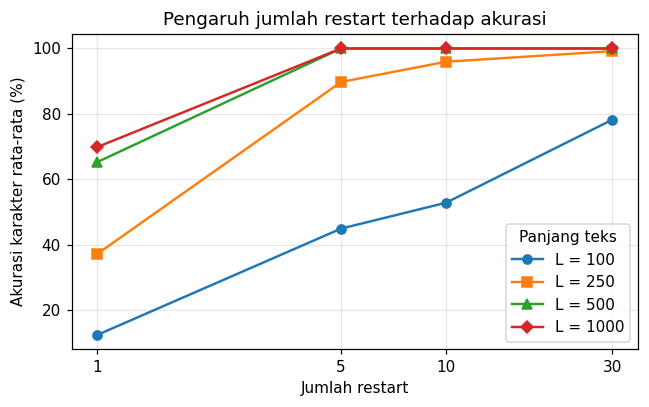

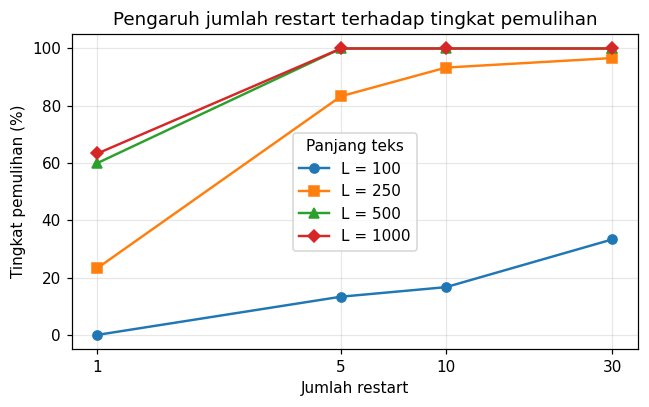

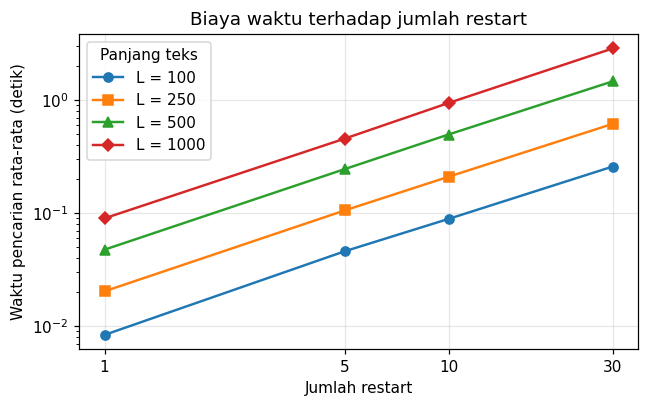

In [ ]:
PENANDA = ['o', 's', '^', 'D']

def grafik_garis(kolom, ylabel, judul, nama, logy=False):
    fig, ax = plt.subplots(figsize=(6, 3.8))
    for n, L in enumerate(PANJANG_TEKS):
        d = ringkas[ringkas.panjang == L]
        ax.plot(d.n_restart, d[kolom], marker=PENANDA[n % 4], lw=1.6, label='L = %d' % L)
    ax.set_xscale('log'); ax.set_xticks(JUMLAH_RESTART); ax.set_xticklabels(JUMLAH_RESTART)
    ax.minorticks_off()
    if logy: ax.set_yscale('log')
    ax.set_xlabel('Jumlah restart'); ax.set_ylabel(ylabel); ax.set_title(judul)
    ax.grid(alpha=.3); ax.legend(title='Panjang teks')
    fig.tight_layout(); fig.savefig(OUT + '/' + nama); plt.show()

grafik_garis('akurasi_rata', 'Akurasi karakter rata-rata (%)',
             'Pengaruh jumlah restart terhadap akurasi', 'gambar_akurasi.png')
grafik_garis('tingkat_pulih', 'Tingkat pemulihan (%)',
             'Pengaruh jumlah restart terhadap tingkat pemulihan', 'gambar_pemulihan.png')
grafik_garis('waktu', 'Waktu pencarian rata-rata (detik)',
             'Biaya waktu terhadap jumlah restart', 'gambar_waktu.png', logy=True)

## 10. Analisis skor vs akurasi

Skor quadgram hanya penunjuk arah, bukan ukuran kebenaran. Setiap hasil akhir dikelompokkan dengan membandingkan skornya terhadap skor plainteks asli:

| Kategori | Kondisi | Arti |
|---|---|---|
| Berhasil | akurasi ≥ ambang | plainteks pulih |
| Gagal pencarian | akurasi < ambang dan skor hasil < skor asli | terjebak optimum lokal; restart tambahan masih bisa membantu |
| Gagal fungsi skor | akurasi < ambang dan skor hasil ≥ skor asli | kandidat salah dinilai lebih "Inggris" daripada plainteks asli; restart tambahan tidak akan membantu |

TABEL VII. Kategori hasil akhir (% cipherteks)


Korelasi Spearman skor vs akurasi, per panjang teks:


/tmp/ipykernel_1588/1270311159.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  kor = df_restart.groupby('panjang').apply(lambda d: d.skor_norm.corr(d.akurasi, method='spearman'))


,rho
panjang,
100,0.497
250,0.846
500,0.876
1000,0.796


Pendakian dengan skor MELEBIHI plainteks asli tetapi dekripsi salah:


,% pendakian
panjang,
100,1.00
250,0.00
500,0.00
1000,0.00


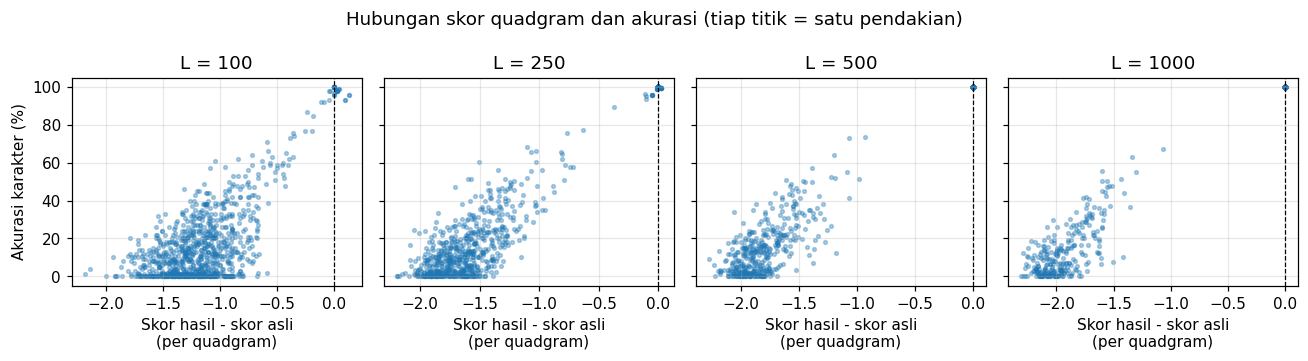

In [ ]:
def kategori(b):
    if b['akurasi'] >= AMBANG_PULIH: return 'Berhasil'
    return 'Gagal fungsi skor' if b['skor'] >= b['skor_asli'] - 1e-9 else 'Gagal pencarian'

df['kategori'] = df.apply(kategori, axis=1)
kat = (df.groupby(['panjang', 'n_restart'])['kategori'].value_counts(normalize=True)
         .mul(100).unstack(fill_value=0)
         .reindex(columns=['Berhasil', 'Gagal pencarian', 'Gagal fungsi skor'], fill_value=0))
kat.to_csv(OUT + '/tabel_kategori_kegagalan.csv')
print('TABEL VII. Kategori hasil akhir (% cipherteks)')
display(kat.style.format('{:.1f}'))

# Korelasi skor (dinormalkan per quadgram) dengan akurasi, pada semua pendakian tunggal.
df_restart['skor_norm'] = df_restart.skor / (df_restart.panjang - 3)
df_restart['selisih'] = (df_restart.skor - df_restart.skor_asli) / (df_restart.panjang - 3)
kor = df_restart.groupby('panjang').apply(lambda d: d.skor_norm.corr(d.akurasi, method='spearman'))
print('Korelasi Spearman skor vs akurasi, per panjang teks:')
display(kor.rename('rho').to_frame().style.format('{:.3f}'))

# Kasus skor hasil > skor asli padahal dekripsi salah.
lebih = df_restart[(df_restart.skor > df_restart.skor_asli + 1e-9) & (df_restart.akurasi < AMBANG_PULIH)]
print('Pendakian dengan skor MELEBIHI plainteks asli tetapi dekripsi salah:')
display((lebih.groupby('panjang').size().reindex(PANJANG_TEKS, fill_value=0) /
         df_restart.groupby('panjang').size() * 100).rename('% pendakian').to_frame().style.format('{:.2f}'))

fig, axes = plt.subplots(1, len(PANJANG_TEKS), figsize=(3 * len(PANJANG_TEKS), 3.3), sharey=True)
for ax, L in zip(np.atleast_1d(axes), PANJANG_TEKS):
    d = df_restart[df_restart.panjang == L]
    ax.scatter(d.selisih, 100 * d.akurasi, s=6, alpha=.35)
    ax.axvline(0, color='k', ls='--', lw=.8)
    ax.set_title('L = %d' % L); ax.set_xlabel('Skor hasil - skor asli\n(per quadgram)'); ax.grid(alpha=.3)
np.atleast_1d(axes)[0].set_ylabel('Akurasi karakter (%)')
fig.suptitle('Hubungan skor quadgram dan akurasi (tiap titik = satu pendakian)')
fig.tight_layout(); fig.savefig(OUT + '/gambar_skor_vs_akurasi.png'); plt.show()

## 11. Coba cipherteks sendiri

Tempel cipherteks berbahasa Inggris pada `CIPHERTEKS`. Spasi dan tanda baca dipertahankan pada tampilan hasil; hanya huruf yang dipakai untuk pencarian.

In [ ]:
CIPHERTEKS = '''
Rtzd zd j dhwlhr phddjoh. Rth vczwn flauq yam scpgd abhl rth xjke iao jqi lcqd juje zqra rth yalhdr
uthlh qa aqh wjq yzqi tzp. Uh dcdghwrhi rtjr rth waih uacxi fh flanhq hbhqrcjxxe fe daphaqh uzrt
hqacot gjrzhqwh jqi j oaai paihx ay rth Hqoxzdt xjqocjoh, fhwjcdh hbhle xhrrhl nhhgd zrd auq tjfzrd.
'''
N_RESTART_DEMO = 30

huruf = ke_angka(normalisasi(CIPHERTEKS))
catatan = random_restart(huruf, N_RESTART_DEMO, np.random.default_rng(SEED))
terbaik = max(catatan, key=lambda c: c['skor'])
kunci = terbaik['kunci']

def terapkan(teks, kunci):
    # Dekripsi sambil mempertahankan spasi, tanda baca, dan besar-kecil huruf.
    out = []
    for ch in teks:
        if 'A' <= ch <= 'Z': out.append(chr(kunci[ord(ch) - 65] + 65))
        elif 'a' <= ch <= 'z': out.append(chr(kunci[ord(ch) - 97] + 97))
        else: out.append(ch)
    return ''.join(out)

print('Panjang (huruf) : %d' % len(huruf))
print('Skor terbaik    : %.2f (%.3f per quadgram)' % (terbaik['skor'], terbaik['skor'] / max(len(huruf) - 3, 1)))
print('Restart mencapai skor terbaik : %d dari %d' %
      (sum(abs(c['skor'] - terbaik['skor']) < 1e-6 for c in catatan), N_RESTART_DEMO))
print('\nCipherteks : ABCDEFGHIJKLMNOPQRSTUVWXYZ')
print('Plainteks  : ' + ke_huruf(kunci))
print('\nHASIL DEKRIPSI:\n' + terapkan(CIPHERTEKS, kunci))

Panjang (huruf) : 239
Skor terbaik    : -1004.34 (-4.256 per quadgram)
Restart mencapai skor terbaik : 13 dari 30

Cipherteks : ABCDEFGHIJKLMNOPQRSTUVWXYZ
Plainteks  : OVUSYBPEDAZRXKGMNTJHWQCLFI

HASIL DEKRIPSI:

This is a secret message. The quick brown fox jumps over the lazy dog and runs away into the forest
where no one can find him. We suspected that the code would be broken eventually by someone with
enough patience and a good model of the English language, because every letter keeps its own habits.

